In [1]:
import math
import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from numba import cuda

ROOT = Path('/home/senji77/akhyar/research/notebooks/ANSW')
SNAPSHOTS = ROOT / 'mc_temperature_snapshots'
OUTPUT = ROOT / 'asd_finite_temperature'
OUTPUT.mkdir(parents=True, exist_ok=True)

J_asd = 1.0
q0_asd = np.pi / 4
D_asd = J_asd * np.tan(q0_asd)
J2_asd = J_asd / (4 * np.cos(q0_asd))
Bz_asd = 0.0

TEMPERATURES = [0.3, 0.5, 1.0]
N_REPLICAS_ASD = 4
N_SAMPLES_ASD = 512
DT_ASD = 0.025
SAMPLE_EVERY_ASD = 5
BLOCK_ASD = (8, 8, 1)

print('CUDA available:', cuda.is_available())
print('Input:', SNAPSHOTS)
print('Output:', OUTPUT)

CUDA available: True
Input: /home/senji77/akhyar/research/notebooks/ANSW/mc_temperature_snapshots
Output: /home/senji77/akhyar/research/notebooks/ANSW/asd_finite_temperature


In [2]:
def target_tag(t):
    return f'{t:.1f}'.replace('.', 'p')


def choose_snapshots(model, t):
    tag = target_tag(t)
    path = SNAPSHOTS / f'spins_{model}_T{tag}.npy'
    spins = np.load(path, mmap_mode='r')
    assert spins.ndim == 5 and spins.shape[-1] == 3

    rng = np.random.default_rng(20261115 + int(t * 1000) + (0 if model == 'dmi' else 10000))
    replica_indices = rng.choice(spins.shape[1], size=N_REPLICAS_ASD, replace=False)
    snapshot_indices = rng.integers(0, spins.shape[0], size=N_REPLICAS_ASD)

    selected = np.stack([
        spins[snapshot_indices[i], replica_indices[i]]
        for i in range(N_REPLICAS_ASD)
    ]).astype(np.float32)

    with np.load(SNAPSHOTS / f'mc_checks_{model}_T{tag}.npz') as checks:
        assert np.isclose(float(checks['temperature']), t)
        assert np.isclose(float(checks['D']), D_asd)
        assert np.isclose(float(checks['J2']), J2_asd)
        assert np.isclose(float(checks['B_z']), Bz_asd)

    return np.ascontiguousarray(selected)

In [3]:
def target_tag(t):
    return f'{t:.1f}'.replace('.', 'p')


def choose_snapshots(model, t):
    tag = target_tag(t)
    path = SNAPSHOTS / f'spins_{model}_T{tag}.npy'
    spins = np.load(path, mmap_mode='r')
    assert spins.ndim == 5 and spins.shape[-1] == 3

    rng = np.random.default_rng(20261115 + int(t * 1000) + (0 if model == 'dmi' else 10000))
    replica_indices = rng.choice(spins.shape[1], size=N_REPLICAS_ASD, replace=False)
    snapshot_indices = rng.integers(0, spins.shape[0], size=N_REPLICAS_ASD)

    selected = np.stack([
        spins[snapshot_indices[i], replica_indices[i]]
        for i in range(N_REPLICAS_ASD)
    ]).astype(np.float32)

    with np.load(SNAPSHOTS / f'mc_checks_{model}_T{tag}.npz') as checks:
        assert np.isclose(float(checks['temperature']), t)
        assert np.isclose(float(checks['D']), D_asd)
        assert np.isclose(float(checks['J2']), J2_asd)
        assert np.isclose(float(checks['B_z']), Bz_asd)

    return np.ascontiguousarray(selected)

In [4]:
@cuda.jit
def rhs_gpu(spins, derivatives, model_id, J, J2, D, Bz):
    x, y, r = cuda.grid(3)

    nx = spins.shape[1]
    ny = spins.shape[2]

    if r >= spins.shape[0] or x >= nx or y >= ny:
        return

    xp = (x + 1) % nx
    xm = (x - 1 + nx) % nx
    yp = (y + 1) % ny
    ym = (y - 1 + ny) % ny

    sx = spins[r, x, y, 0]
    sy = spins[r, x, y, 1]
    sz = spins[r, x, y, 2]

    hx = J * (
        spins[r, xp, y, 0] + spins[r, xm, y, 0]
        + spins[r, x, yp, 0] + spins[r, x, ym, 0]
    )

    hy = J * (
        spins[r, xp, y, 1] + spins[r, xm, y, 1]
        + spins[r, x, yp, 1] + spins[r, x, ym, 1]
    )

    hz = J * (
        spins[r, xp, y, 2] + spins[r, xm, y, 2]
        + spins[r, x, yp, 2] + spins[r, x, ym, 2]
    ) + Bz

    if model_id == 0:
        hy += D * (spins[r, xp, y, 2] - spins[r, xm, y, 2])
        hz -= D * (spins[r, xp, y, 1] - spins[r, xm, y, 1])
    else:
        xpp = (x + 2) % nx
        xmm = (x - 2 + nx) % nx

        hx -= J2 * (spins[r, xpp, y, 0] + spins[r, xmm, y, 0])
        hy -= J2 * (spins[r, xpp, y, 1] + spins[r, xmm, y, 1])
        hz -= J2 * (spins[r, xpp, y, 2] + spins[r, xmm, y, 2])

    derivatives[r, x, y, 0] = -(sy * hz - sz * hy)
    derivatives[r, x, y, 1] = -(sz * hx - sx * hz)
    derivatives[r, x, y, 2] = -(sx * hy - sy * hx)


@cuda.jit
def rk4_stage_gpu(spins, derivative, output, factor):
    x, y, r = cuda.grid(3)

    if r >= spins.shape[0] or x >= spins.shape[1] or y >= spins.shape[2]:
        return

    ax = spins[r, x, y, 0] + factor * derivative[r, x, y, 0]
    ay = spins[r, x, y, 1] + factor * derivative[r, x, y, 1]
    az = spins[r, x, y, 2] + factor * derivative[r, x, y, 2]

    inv = 1.0 / math.sqrt(ax * ax + ay * ay + az * az)

    output[r, x, y, 0] = ax * inv
    output[r, x, y, 1] = ay * inv
    output[r, x, y, 2] = az * inv


@cuda.jit
def rk4_finish_gpu(spins, k1, k2, k3, k4, dt):
    x, y, r = cuda.grid(3)

    if r >= spins.shape[0] or x >= spins.shape[1] or y >= spins.shape[2]:
        return

    factor = dt / 6.0

    ax = spins[r, x, y, 0] + factor * (
        k1[r, x, y, 0] + 2.0 * k2[r, x, y, 0]
        + 2.0 * k3[r, x, y, 0] + k4[r, x, y, 0]
    )

    ay = spins[r, x, y, 1] + factor * (
        k1[r, x, y, 1] + 2.0 * k2[r, x, y, 1]
        + 2.0 * k3[r, x, y, 1] + k4[r, x, y, 1]
    )

    az = spins[r, x, y, 2] + factor * (
        k1[r, x, y, 2] + 2.0 * k2[r, x, y, 2]
        + 2.0 * k3[r, x, y, 2] + k4[r, x, y, 2]
    )

    inv = 1.0 / math.sqrt(ax * ax + ay * ay + az * az)

    spins[r, x, y, 0] = ax * inv
    spins[r, x, y, 1] = ay * inv
    spins[r, x, y, 2] = az * inv

In [5]:
def energy_per_spin(spins, model):
    xp = np.roll(spins, -1, axis=1)
    yp = np.roll(spins, -1, axis=2)

    energy = -J_asd * np.sum(spins * (xp + yp), axis=(1, 2, 3), dtype=np.float64)

    if model == "dmi":
        energy += D_asd * np.sum(
            spins[..., 2] * xp[..., 1] - spins[..., 1] * xp[..., 2],
            axis=(1, 2), dtype=np.float64
        )
    else:
        xpp = np.roll(spins, -2, axis=1)
        energy += J2_asd * np.sum(spins * xpp, axis=(1, 2, 3), dtype=np.float64)

    energy -= Bz_asd * np.sum(spins[..., 2], axis=(1, 2), dtype=np.float64)

    return energy / (spins.shape[1] * spins.shape[2])


def rk4_step_cuda(d_spins, arrays, grid, model_id):
    d_stage, k1, k2, k3, k4 = arrays

    args = (model_id, np.float32(J_asd), np.float32(J2_asd),
            np.float32(D_asd), np.float32(Bz_asd))

    rhs_gpu[grid, BLOCK_ASD](d_spins, k1, *args)
    rk4_stage_gpu[grid, BLOCK_ASD](d_spins, k1, d_stage, np.float32(DT_ASD / 2))
    rhs_gpu[grid, BLOCK_ASD](d_stage, k2, *args)
    rk4_stage_gpu[grid, BLOCK_ASD](d_spins, k2, d_stage, np.float32(DT_ASD / 2))
    rhs_gpu[grid, BLOCK_ASD](d_stage, k3, *args)
    rk4_stage_gpu[grid, BLOCK_ASD](d_spins, k3, d_stage, np.float32(DT_ASD))
    rhs_gpu[grid, BLOCK_ASD](d_stage, k4, *args)
    rk4_finish_gpu[grid, BLOCK_ASD](d_spins, k1, k2, k3, k4, np.float32(DT_ASD))

In [6]:
def run_asd(model, starting_spins):
    model_id = 0 if model == "dmi" else 1
    nrep, nx, ny, _ = starting_spins.shape

    grid = (
        (nx + BLOCK_ASD[0] - 1) // BLOCK_ASD[0],
        (ny + BLOCK_ASD[1] - 1) // BLOCK_ASD[1],
        nrep
    )

    d_spins = cuda.to_device(np.ascontiguousarray(starting_spins, dtype=np.float32))
    arrays = [cuda.device_array_like(d_spins) for _ in range(5)]

    fourier_time = np.empty(
        (nrep, N_SAMPLES_ASD, nx, ny, 3),
        dtype=np.complex64
    )

    t_diagnostics = []
    e_diagnostics = []
    initial_energy = energy_per_spin(starting_spins, model)
    start = time.perf_counter()

    for sample in range(N_SAMPLES_ASD):
        if sample > 0:
            for _ in range(SAMPLE_EVERY_ASD):
                rk4_step_cuda(d_spins, arrays, grid, model_id)

        current = d_spins.copy_to_host()
        fourier_time[:, sample] = (
            np.fft.fft2(current, axes=(1, 2)) / np.sqrt(nx * ny)
        ).astype(np.complex64)

        if sample % 64 == 0 or sample == N_SAMPLES_ASD - 1:
            t_diagnostics.append(sample * DT_ASD * SAMPLE_EVERY_ASD)
            e_diagnostics.append(energy_per_spin(current, model))

        if (sample + 1) % 128 == 0 or sample + 1 == N_SAMPLES_ASD:
            print(f"{model}: {sample + 1}/{N_SAMPLES_ASD} samples", flush=True)

    final_spins = d_spins.copy_to_host()
    final_energy = energy_per_spin(final_spins, model)
    drift = np.max(
        np.abs(final_energy - initial_energy)
        / np.maximum(np.abs(initial_energy), 1e-10)
    )
    norm_error = np.max(np.abs(np.linalg.norm(final_spins, axis=-1) - 1))

    print(model, "max relative energy drift:", drift)
    print(model, "max spin norm error:", norm_error)
    print(model, "elapsed seconds:", time.perf_counter() - start)

    if drift > 5e-3:
        raise RuntimeError(f"Energy drift too large for {model}: {drift}")

    return fourier_time, np.array(t_diagnostics), np.array(e_diagnostics)

In [7]:
def dynamical_structure_factor(fourier_time):
    nrep, nt, nx, ny, _ = fourier_time.shape
    sample_dt = DT_ASD * SAMPLE_EVERY_ASD

    window = np.hanning(nt).astype(np.float32)
    norm_factor = sample_dt / (nt * np.mean(window ** 2))

    omega_full = 2 * np.pi * np.fft.fftfreq(nt, sample_dt)
    positive = omega_full >= 0
    spectrum = np.zeros((np.count_nonzero(positive), nx, ny), dtype=np.float64)

    for component in range(3):
        series = fourier_time[..., component].copy()
        series -= series.mean(axis=1, keepdims=True)
        series *= window[None, :, None, None]

        transform = np.fft.fft(series, axis=1)[:, positive]
        spectrum += np.mean(np.abs(transform) ** 2, axis=0)

    spectrum *= norm_factor
    spectrum = np.fft.fftshift(spectrum, axes=(1, 2))

    qx = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(nx))
    qy = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(ny))

    return qx, qy, omega_full[positive], spectrum.astype(np.float32)

In [8]:
for T_ASD in TEMPERATURES:
    tag = target_tag(T_ASD)
    spectra = {}
    diagnostics = {}

    for model in ['dmi', 'frustration']:
        spins = choose_snapshots(model, T_ASD)
        fourier, times, energies = run_asd(model, spins)
        qx, qy, omega, spectrum = dynamical_structure_factor(fourier)
        spectra[model] = spectrum
        diagnostics[model] = (times, energies)
        del fourier, spins

    np.savez_compressed(
        OUTPUT / f'asd_dynamical_structure_factor_T{tag}.npz',
        qx=qx,
        qy=qy,
        omega=omega,
        S_dmi=spectra['dmi'],
        S_frustration=spectra['frustration'],
        temperature=T_ASD,
        dt=DT_ASD,
        sample_every=SAMPLE_EVERY_ASD,
        n_samples=N_SAMPLES_ASD,
        n_replicas=N_REPLICAS_ASD,
        J=J_asd,
        D=D_asd,
        J2=J2_asd,
        B_z=Bz_asd,
        energy_time_dmi=diagnostics['dmi'][0],
        energy_dmi=diagnostics['dmi'][1],
        energy_time_frustration=diagnostics['frustration'][0],
        energy_frustration=diagnostics['frustration'][1]
    )

    for model in ['dmi', 'frustration']:
        times, energies = diagnostics[model]
        drift = np.max(
            np.abs(energies - energies[0])
            / np.maximum(np.abs(energies[0]), 1e-10)
        )
        print(f'T={T_ASD:.1f} {model} max relative energy drift={drift:.6e}')

    print('Saved T=', T_ASD, flush=True)

dmi: 128/512 samples
dmi: 256/512 samples
dmi: 384/512 samples
dmi: 512/512 samples
dmi max relative energy drift: 4.998392960434325e-05
dmi max spin norm error: 5.9604645e-08
dmi elapsed seconds: 2.2143694579717703
frustration: 128/512 samples
frustration: 256/512 samples
frustration: 384/512 samples
frustration: 512/512 samples
frustration max relative energy drift: 1.3927282604345311e-05
frustration max spin norm error: 5.9604645e-08
frustration elapsed seconds: 1.2943961989949457
T=0.3 dmi max relative energy drift=4.998393e-05
T=0.3 frustration max relative energy drift=1.392728e-05
Saved T= 0.3
dmi: 128/512 samples
dmi: 256/512 samples
dmi: 384/512 samples
dmi: 512/512 samples
dmi max relative energy drift: 6.128549881183515e-05
dmi max spin norm error: 5.9604645e-08
dmi elapsed seconds: 1.330929615010973
frustration: 128/512 samples
frustration: 256/512 samples
frustration: 384/512 samples
frustration: 512/512 samples
frustration max relative energy drift: 1.5554015054884064e-05

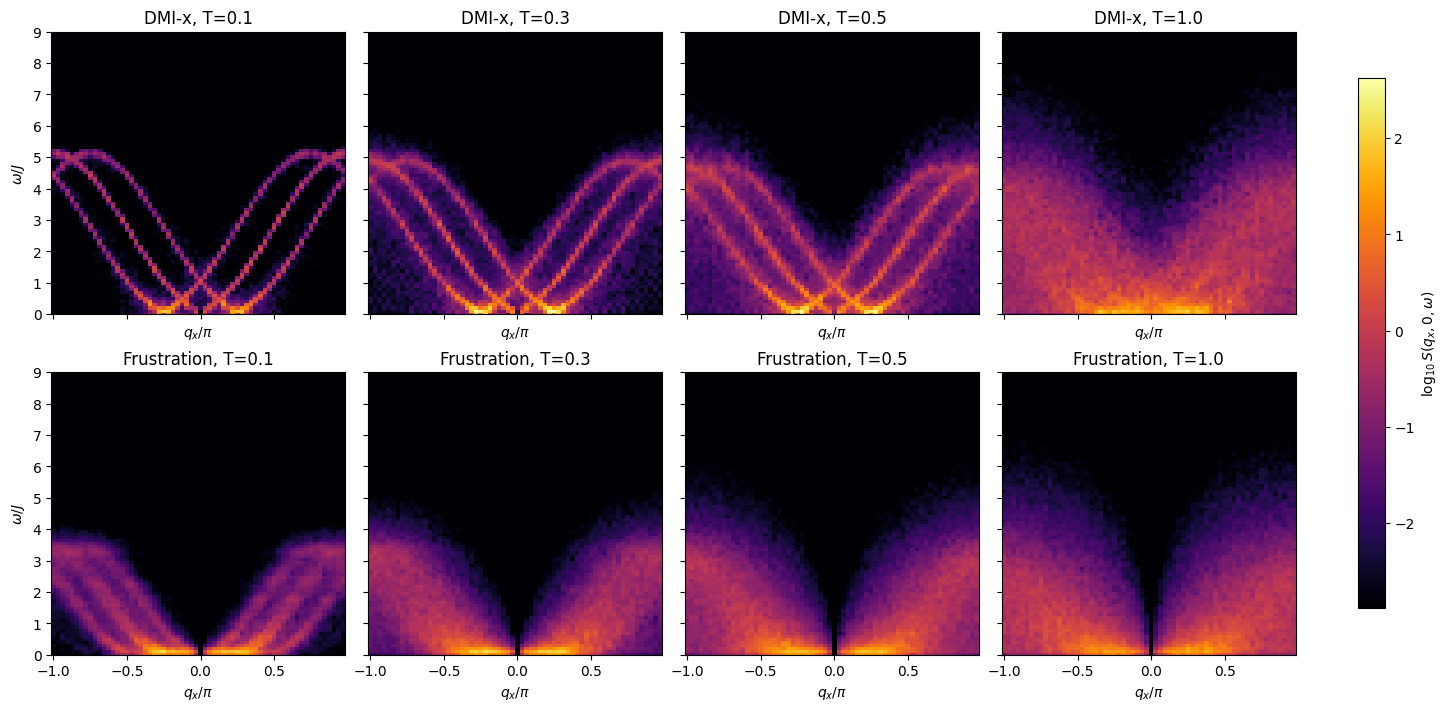

In [9]:
all_data = {}
old_file = ROOT / 'asd_2d_results' / 'asd_dynamical_structure_factor_T0p1.npz'

if old_file.exists():
    with np.load(old_file) as data:
        all_data[0.1] = {
            'omega': data['omega'].copy(),
            'qx': data['qx'].copy(),
            'qy': data['qy'].copy(),
            'dmi': data['S_dmi'].copy(),
            'frustration': data['S_frustration'].copy()
        }

for t in TEMPERATURES:
    with np.load(OUTPUT / f'asd_dynamical_structure_factor_T{target_tag(t)}.npz') as data:
        all_data[t] = {
            'omega': data['omega'].copy(),
            'qx': data['qx'].copy(),
            'qy': data['qy'].copy(),
            'dmi': data['S_dmi'].copy(),
            'frustration': data['S_frustration'].copy()
        }

plot_temps = sorted(all_data)
values = np.concatenate([
    np.array([np.max(all_data[t][model])])
    for t in plot_temps for model in ['dmi', 'frustration']
])
vmax = np.log10(values.max() + 1e-12)
vmin = vmax - 5.5

fig, axes = plt.subplots(2, len(plot_temps), figsize=(3.6 * len(plot_temps), 7), sharex=True, sharey=True, constrained_layout=True)
axes = np.asarray(axes).reshape(2, len(plot_temps))

for col, t in enumerate(plot_temps):
    data = all_data[t]
    iy = np.argmin(np.abs(data['qy']))

    for row, (model, title) in enumerate([('dmi', 'DMI-x'), ('frustration', 'Frustration')]):
        ax = axes[row, col]
        image = ax.pcolormesh(
            data['qx'] / np.pi, data['omega'],
            np.log10(data[model][:, :, iy] + 1e-12),
            shading='auto', cmap='inferno', vmin=vmin, vmax=vmax
        )
        ax.set_title(f'{title}, T={t:.1f}')
        ax.set_ylim(0, 9)
        ax.set_xlabel(r'$q_x/\pi$')
        if col == 0:
            ax.set_ylabel(r'$\omega/J$')

fig.colorbar(image, ax=axes, location='right', shrink=0.85, label=r'$\log_{10} S(q_x,0,\omega)$')
fig.savefig(OUTPUT / 'finiteT_asd_qy0_comparison.png', dpi=300, bbox_inches='tight')
fig.savefig(OUTPUT / 'finiteT_asd_qy0_comparison.pdf', bbox_inches='tight')
plt.show()

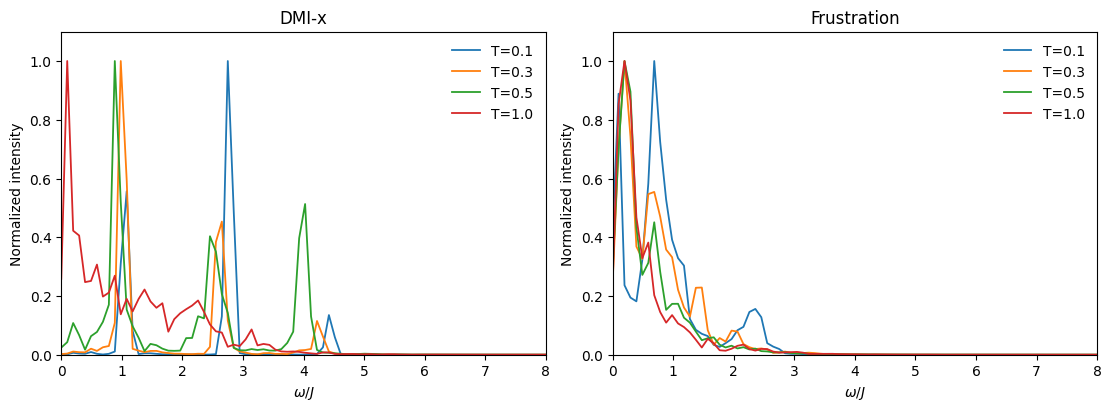

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)

for ax, model, name in zip(axes, ['dmi', 'frustration'], ['DMI-x', 'Frustration']):
    for t in plot_temps:
        data = all_data[t]
        ix = np.argmin(np.abs(data['qx'] - np.pi / 2))
        iy = np.argmin(np.abs(data['qy']))
        curve = data[model][:, ix, iy]
        normalized = curve / max(float(curve.max()), 1e-10)
        ax.plot(data['omega'], normalized, label=f'T={t:.1f}', lw=1.3)

    ax.set_xlim(0, 8)
    ax.set_ylim(0, 1.1)
    ax.set_title(name)
    ax.set_xlabel(r'$\omega/J$')
    ax.set_ylabel('Normalized intensity')
    ax.legend(frameon=False)

fig.savefig(OUTPUT / 'finiteT_asd_peak_profiles.png', dpi=300, bbox_inches='tight')
fig.savefig(OUTPUT / 'finiteT_asd_peak_profiles.pdf', bbox_inches='tight')
plt.show()

In [11]:
for t in plot_temps:
    data = all_data[t]
    ix = np.argmin(np.abs(data['qx'] - np.pi / 2))
    iy = np.argmin(np.abs(data['qy']))

    for model in ['dmi', 'frustration']:
        profile = data[model][:, ix, iy]
        mask = (data['omega'] >= 0.3) & (data['omega'] <= 8.0)
        if np.any(mask):
            peak = np.argmax(profile[mask])
            print(f'T={t:.1f} {model:12s} dominant peak={data["omega"][mask][peak]:.4f}')
        else:
            print(f'T={t:.1f} {model:12s} insufficient frequency grid')

print('Results:', OUTPUT)

T=0.1 dmi          dominant peak=2.7489
T=0.1 frustration  dominant peak=0.6872
T=0.3 dmi          dominant peak=0.9817
T=0.3 frustration  dominant peak=0.6872
T=0.5 dmi          dominant peak=0.8836
T=0.5 frustration  dominant peak=0.6872
T=1.0 dmi          dominant peak=0.5890
T=1.0 frustration  dominant peak=0.3927
Results: /home/senji77/akhyar/research/notebooks/ANSW/asd_finite_temperature


In [12]:

from pathlib import Path
import numpy as np

folder = Path("asd_finite_temperature")

for file in sorted(folder.rglob("*.npz")):
    print("\n", file)

    with np.load(file) as data:
        for key in data.files:
            print(key, data[key].shape)



 asd_finite_temperature/asd_dynamical_structure_factor_T0p3.npz
qx (64,)
qy (64,)
omega (256,)
S_dmi (256, 64, 64)
S_frustration (256, 64, 64)
temperature ()
dt ()
sample_every ()
n_samples ()
n_replicas ()
J ()
D ()
J2 ()
B_z ()
energy_time_dmi (9,)
energy_dmi (9, 4)
energy_time_frustration (9,)
energy_frustration (9, 4)

 asd_finite_temperature/asd_dynamical_structure_factor_T0p5.npz
qx (64,)
qy (64,)
omega (256,)
S_dmi (256, 64, 64)
S_frustration (256, 64, 64)
temperature ()
dt ()
sample_every ()
n_samples ()
n_replicas ()
J ()
D ()
J2 ()
B_z ()
energy_time_dmi (9,)
energy_dmi (9, 4)
energy_time_frustration (9,)
energy_frustration (9, 4)

 asd_finite_temperature/asd_dynamical_structure_factor_T1p0.npz
qx (64,)
qy (64,)
omega (256,)
S_dmi (256, 64, 64)
S_frustration (256, 64, 64)
temperature ()
dt ()
sample_every ()
n_samples ()
n_replicas ()
J ()
D ()
J2 ()
B_z ()
energy_time_dmi (9,)
energy_dmi (9, 4)
energy_time_frustration (9,)
energy_frustration (9, 4)
